# Random Forest

### Author
   * Jonathan Sancho Loaiza

## Problem Analysis (CRISP-DM 1: Business Understanding)

Knowing the income of a person is useful and, at the same time, one of the
hardest things to ask directly. A bank that wants to offer a premium product, a
public office that plans a subsidy and a survey that has to be corrected for
non response all face the same situation: they hold a description of the person,
their age, their studies, their occupation, their marital situation and the
hours they work, but not what that person earns.

The goal of this notebook is to build a model that classifies a person into one
of two groups from those attributes alone: someone who earns more than 50000
dollars a year and someone who does not. The response variable is `income`,
which the dataset codes as the two strings `<=50K` and `>50K`, and every other
column is a candidate predictor.

The data is the census extract known as Adult, with 32561 records described by
14 attributes. The class of interest is the person above 50000 dollars, who is
the minority: roughly one record in four. That imbalance sets the bar for the
whole notebook, because answering that nobody earns more than 50000 already
gives an accuracy close to 76 percent, so accuracy alone will never be enough to
say that a model works.

The technique used here is the random forest, which grows many decision trees,
each one on a random sample of the records and choosing among a random subset
of the variables at each node, and then lets them vote. It is chosen because
the predictors of this dataset are of every kind, ordered numbers such as the
age, counts such as the hours per week, extremely skewed amounts such as the
capital gain and unordered categories such as the occupation, and a forest
handles that mixture without scaling anything and without assuming any shape
for the relationship. The price is that the model cannot be read as a single
chain of questions, so the section on variable importance replaces that
reading.

### Libraries

In [1]:
# Dataset handling
import os
import pandas as pd
import numpy as np

# Plots
import matplotlib.pyplot as plt
import seaborn as sns

# Model
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

# Split and validation
from sklearn.model_selection import (train_test_split, cross_val_score,
                                     cross_val_predict)

# Evaluation
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, precision_score, recall_score,
                             f1_score, roc_curve, roc_auc_score)

# Model persistence
import joblib

# Same seed everywhere, so the notebook gives the same numbers on every run
SEED = 4161
np.random.seed(SEED)

## Data Understanding (CRISP-DM 2)

The file `income_evaluation.csv` is the Adult dataset, built from the 1994
census of the United States. Each row is one surveyed person and each column one
attribute recorded about that person, their household or their job.

In [3]:
# Load the data. The file is read from the notebook's own folder, and if it is
# not there the Colab sample_data folder is tried, so the notebook runs in both
FILE = 'income_evaluation.csv'
path = FILE if os.path.exists(FILE) else '/content/sample_data/' + FILE
income = pd.read_csv(path, skipinitialspace=True)

# First records
income.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


The first rows already show the two kinds of column the dataset mixes. Some are
plain numbers, such as `age`, `education-num`, `capital-gain`, `capital-loss`
and `hours-per-week`, and some are text that names a category, such as
`workclass` with values like `State-gov` or `Private`, or `occupation` with
values like `Adm-clerical` or `Exec-managerial`.

The column `income` is the one to predict. It holds the two strings `<=50K` and
`>50K`, which are the two sides of the 50000 dollars a year the assignment asks
about, and it is not a number, so the preparation section has to recode it.

The blanks that this file writes after every comma are worth insisting on. The
value stored for the first record is ` State-gov` with a leading space, and
without `skipinitialspace=True` every comparison written later in the notebook,
every table of shares by category and every indicator column would be built on
strings that look right on screen and do not match anything.

In [ ]:
# Number of records
print("Record count:", len(income))
# Number of columns
print("Column count:", len(income.columns))
# Rows and columns
print("Rows and columns:", income.shape)
# Dataset information
income.info()

Record count: 32561
Column count: 15
Rows and columns: (32561, 15)
<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education-num   32561 non-null  int64
 5   marital-status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital-gain    32561 non-null  int64
 11  capital-loss    32561 non-null  int64
 12  hours-per-week  32561 non-null  int64
 13  native-country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


The dataset has 32561 records and 15 columns, so 14 possible predictors plus the
response. The `info()` output lists, for every column, how many values are not
empty and which type pandas assigned to it. Six columns are whole numbers and
nine are text, reported as `str` or as `object` depending on the version of
pandas, and all fifteen report 32561 non null values.

That last number is the first thing to check and, in this file, the first thing
that misleads. Nothing is empty, but the next cell shows that this dataset does
not leave a cell empty when it does not know something.

In [ ]:
# Check for empty values
print("Columns with an empty cell:", income.isnull().any().sum(),
      ' / ', len(income.columns))

# This file does not leave a cell empty, it writes a question mark instead, so
# the missing values have to be counted by hand
unknown = (income == '?').sum()
print("\nValues written as '?':")
print(unknown[unknown > 0])
print("\nRecords with at least one '?':", (income == '?').any(axis=1).sum())

Columns with an empty cell: 0  /  15

Values written as '?':
workclass         1836
occupation        1843
native-country     583
dtype: int64

Records with at least one '?': 2399


The count on the first line is zero: no column of the file has an empty cell, so
a routine check for missing values would report a complete dataset and move on.

The file writes a question mark instead. Three columns use it: `workclass` in
1836 records, `occupation` in 1843 and `native-country` in 583, and 2399
records, 7.4 percent of the file, carry at least one of them. The 1836 records
with an unknown workclass are exactly the same records that have an unknown
occupation, which is what one would expect, since a person outside the labour
market has neither.

Those 2399 records are kept, and `?` is treated as one more level of its
category rather than as a value to be filled in. There are two reasons. The
first is that the unknown level is not silent: the table of shares below gives
0.104 of people above 50000 for the unknown workclass, clearly below the 0.219
of the private sector and well above the zero of the two levels that report no
work at all, so the absence itself carries information about the person. The
second is that a decision tree can split on that level like on any other, so
nothing has to be invented to make the model run.

In [ ]:
# Check for duplicated records
print("Duplicated rows:", income.duplicated().sum())

# The records involved, sorted so the pairs sit next to each other
duplicates = income[income.duplicated(keep=False)]
duplicates.sort_values(list(income.columns)).head(10)

Duplicated rows: 24


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
17673,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K
18698,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K
6990,19,Private,138153,Some-college,10,Never-married,Adm-clerical,Own-child,White,Female,0,0,10,United-States,<=50K
21318,19,Private,138153,Some-college,10,Never-married,Adm-clerical,Own-child,White,Female,0,0,10,United-States,<=50K
15189,19,Private,146679,Some-college,10,Never-married,Exec-managerial,Own-child,Black,Male,0,0,30,United-States,<=50K
21490,19,Private,146679,Some-college,10,Never-married,Exec-managerial,Own-child,Black,Male,0,0,30,United-States,<=50K
3917,19,Private,251579,Some-college,10,Never-married,Other-service,Own-child,White,Male,0,0,14,United-States,<=50K
31993,19,Private,251579,Some-college,10,Never-married,Other-service,Own-child,White,Male,0,0,14,United-States,<=50K
5805,20,Private,107658,Some-college,10,Never-married,Tech-support,Not-in-family,White,Female,0,0,10,United-States,<=50K
11631,20,Private,107658,Some-college,10,Never-married,Tech-support,Not-in-family,White,Female,0,0,10,United-States,<=50K


There are 24 repeated rows. The listing shows what they look like: young people,
most of them 19 or 20 years old, with a common combination of attributes, no
capital gain and the standard hours, which is exactly the profile that repeats
itself by chance in a census of 32561 people described by 14 attributes.

They are almost certainly different people rather than a mistake in the file,
since the dataset carries no identifier that would let anyone tell. The reason
to remove them is different: a row that appears twice can land in the training
set and in the test set at the same time, which would let the model be graded on
a record it had already seen. One copy of each is kept.

In [ ]:
# A repeated row would put the same person in training and in test, so one copy
# of each is kept
income = income.drop_duplicates().reset_index(drop=True)
print("Records after removing duplicates:", len(income))

Records after removing duplicates: 32537


Class counts:
income
<=50K    24698
>50K      7839
Name: count, dtype: int64

Class share:
income
<=50K    0.759
>50K     0.241
Name: proportion, dtype: float64


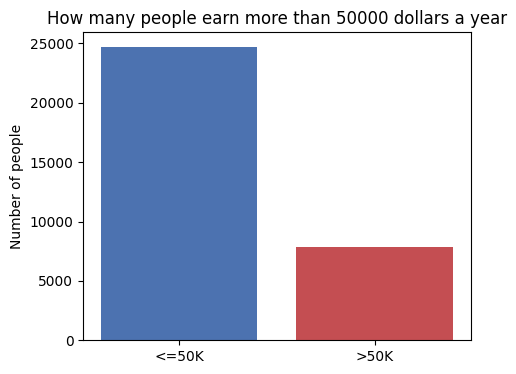

In [ ]:
# How the response variable is distributed
counts = income['income'].value_counts()
print("Class counts:")
print(counts)
print("\nClass share:")
print(income['income'].value_counts(normalize=True).round(3))

plt.figure(figsize=(5, 4))
plt.bar(['<=50K', '>50K'], [counts['<=50K'], counts['>50K']],
        color=['#4c72b0', '#c44e52'])
plt.title('How many people earn more than 50000 dollars a year')
plt.ylabel('Number of people')
plt.show()

The bar chart counts people in each class, with the height of the bar being the
number of records. There are 24698 people at or below 50000 dollars and 7839
above, that is 75.9 percent against 24.1 percent.

That imbalance is the reference for everything that follows. A model that always
answered that the person earns at most 50000, without looking at a single
variable, would already be right 75.9 percent of the time, so an accuracy of
0.759 is the floor and not a result. The interesting question is how many of the
7839 people above 50000 a model can find, and the evaluation section is built
around that number rather than around accuracy.

## Data Exploration (CRISP-DM 2) and Data Preparation (CRISP-DM 3)

The exploration answers two questions at the same time: which variables carry
information about the income, and which columns have to be changed before a
model can read them. The decisions taken here are the preparation, and each one
is stated with the evidence that produced it.

In [ ]:
# Summary of the numeric columns
income.describe().T

,count,mean,std,min,25%,50%,75%,max
age,32537.0,38.585549,13.637984,17.0,28.0,37.0,48.0,90.0
fnlwgt,32537.0,189780.848511,105556.471009,12285.0,117827.0,178356.0,236993.0,1484705.0
education-num,32537.0,10.081815,2.571633,1.0,9.0,10.0,12.0,16.0
capital-gain,32537.0,1078.443741,7387.957424,0.0,0.0,0.0,0.0,99999.0
capital-loss,32537.0,87.368227,403.101833,0.0,0.0,0.0,0.0,4356.0
hours-per-week,32537.0,40.440329,12.346889,1.0,40.0,40.0,45.0,99.0


Each row of this table is a numeric column and each column a statistic: the
count of values, the mean, the standard deviation, the smallest value, the three
quartiles and the largest value.

The people are 38.6 years old on average, between 17 and 90. `education-num` is
an ordered code that runs from 1 to 16 with a mean of 10.1, and the cell below
shows what those codes name. The hours per week average 40.4, which is the
standard working week, but the column reaches from 1 to 99, so it holds both
marginal jobs and extreme ones.

The two capital columns are different in kind from the rest. `capital-gain` has
a mean of 1078 with a standard deviation of 7388 and a maximum of 99999, and its
three quartiles are all zero, which means that more than three quarters of the
records hold no gain at all and the mean is produced by a small minority.
`capital-loss` behaves the same way. A column whose median and third quartile
are both zero is not a measurement that varies from person to person, it is a
flag that is off for almost everybody, and the next cell measures it as such.

`fnlwgt` runs from 12285 to 1484705 with a mean near 190000. It is the only
column here that does not describe the person at all, and it is dealt with
further down.

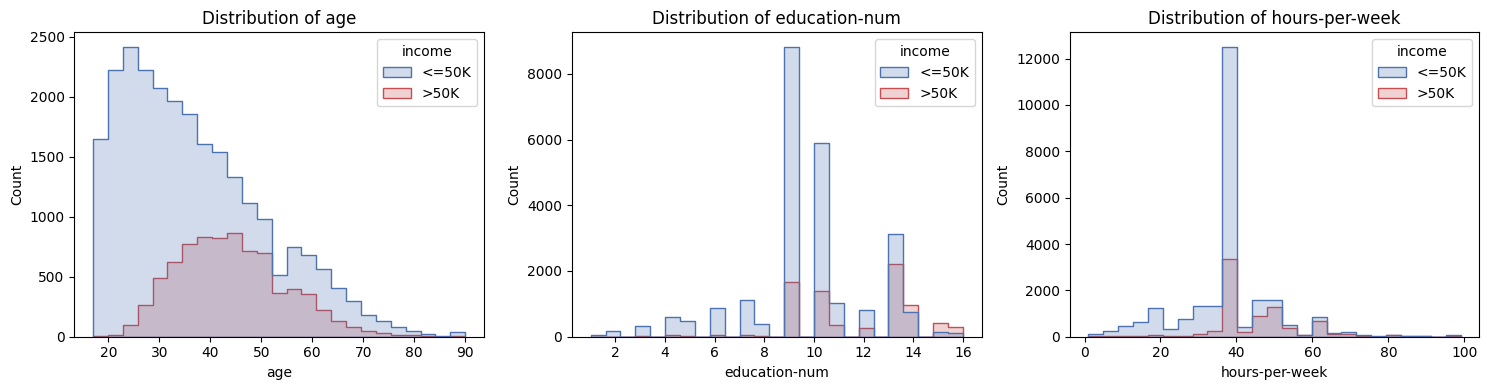

In [ ]:
# Distribution of the three main numeric variables, split by class
numeric_main = ['age', 'education-num', 'hours-per-week']

plt.figure(figsize=(15, 4))
for i, column in enumerate(numeric_main, start=1):
    plt.subplot(1, 3, i)
    sns.histplot(data=income, x=column, hue='income', bins=25,
                 palette=['#4c72b0', '#c44e52'], element='step')
    plt.title('Distribution of ' + column)
plt.tight_layout()
plt.show()

Each panel is a histogram: the horizontal axis is the value of the variable, the
height of a bar is how many people fall in that range, and the two colors are
the two classes, blue for the people at or below 50000 and red for the ones
above. Because there are more than three times as many people in the first
class, the blue curve is taller almost everywhere and what matters is the shape,
not the height.

Age is the clearest of the three. The blue curve peaks in the twenties and falls
from there, while the red one is almost absent below 25, rises to a maximum
around 40 to 50 and only then declines, so the people above 50000 are
concentrated in the middle of the working life.

`education-num` shows the same idea in steps rather than as a curve. The two
tall blue bars at 9 and 10, which are high school and some college, hold most of
the first class, while the red mass sits at 13 and above, which is a bachelor
degree onwards.

The hours per week are the least separated of the three. Both classes spike at
40, which is the standard week and the value most people report, and the
difference is in what happens to the right of that spike, where the red curve
keeps a visible weight that the blue one loses.

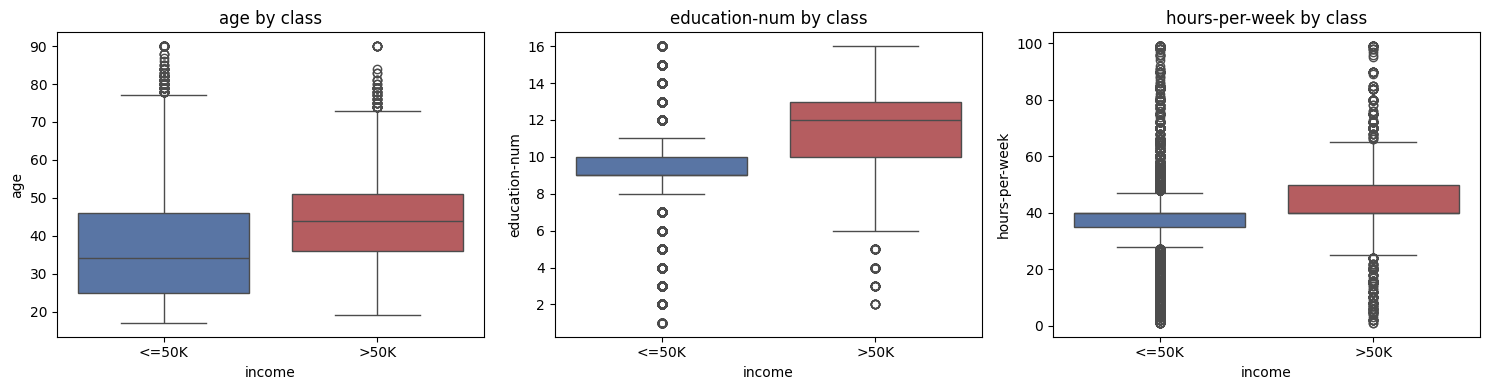

         age  education-num  hours-per-week
income                                     
<=50K   34.0            9.0            40.0
>50K    44.0           12.0            40.0


In [ ]:
# The same three variables as box plots, one box per class
plt.figure(figsize=(15, 4))
for i, column in enumerate(numeric_main, start=1):
    plt.subplot(1, 3, i)
    sns.boxplot(data=income, x='income', y=column, hue='income',
                palette=['#4c72b0', '#c44e52'], legend=False)
    plt.title(column + ' by class')
plt.tight_layout()
plt.show()

# The numbers behind the boxes
print(income.groupby('income')[numeric_main].median())

A box plot summarises a variable with five numbers. The box goes from the first
quartile to the third quartile, so it holds the middle half of the people, the
line inside the box is the median, the whiskers reach out to the most extreme
values that are still close to the box, and the dots beyond them are the
observations that sit far from the rest.

The medians printed under the plots put numbers on the histograms. The people
above 50000 are ten years older, 44 against 34, and their education code is 12
against 9, which is an associate degree against a high school diploma.

The third median is the interesting one: 40 hours per week in both classes, so
read through its center alone the variable would look useless. The quartiles say
otherwise. For the first class the middle half runs from 35 to 40 hours and for
the second from 40 to 50, and the means are 38.8 and 45.5. The signal of this
variable is in the upper half of its range, not in its center, which is exactly
the kind of relationship that a tree can use, since a tree cuts the variable at
a value instead of assuming that more hours always mean more income.

In [ ]:
# The two capital columns behave differently from the rest
for column in ['capital-gain', 'capital-loss']:
    zeros = (income[column] == 0).mean()
    print(column, " share of records at zero:", round(zeros, 3))
    non_zero = income[income[column] > 0]
    print("   median when it is not zero:", non_zero[column].median())
    print("   share above 50K when it is zero:",
          round((income[income[column] == 0]['income'] == '>50K').mean(), 3))
    print("   share above 50K when it is not zero:",
          round((non_zero['income'] == '>50K').mean(), 3))
    print()

print("Records at the maximum capital gain of 99999:",
      (income['capital-gain'] == 99999).sum())
print("   share of them above 50K:",
      round((income[income['capital-gain'] == 99999]['income'] == '>50K').mean(), 3))

capital-gain  share of records at zero: 0.917
   median when it is not zero: 7298.0
   share above 50K when it is zero: 0.207
   share above 50K when it is not zero: 0.618

capital-loss  share of records at zero: 0.953
   median when it is not zero: 1887.0
   share above 50K when it is zero: 0.228
   share above 50K when it is not zero: 0.509

Records at the maximum capital gain of 99999: 159
   share of them above 50K: 1.0


This cell measures what the quartiles of the summary table announced. The
capital gain is zero for 91.7 percent of the people and the capital loss for
95.3 percent, so both behave as a flag rather than as a measurement.

The flag is a strong one. Among the people with no capital gain, 20.7 percent
earn more than 50000; among the ones who declare a gain, 61.8 percent do, three
times as many, and the median gain they declare is 7298 dollars. The capital
loss splits the classes the same way, 22.8 percent against 50.9 percent. Both
columns are kept as they are, because a tree can cut them at zero by itself and
recover exactly this distinction without any transformation.

The last two lines are a warning rather than a result. There are 159 records
whose capital gain is exactly 99999, and every single one of them is above
50000. That value is not a real amount, it is the top code the census uses to
avoid publishing the highest incomes, so it is a label of the answer that
travels inside a predictor. It is left in the data because removing it would
change the dataset that the assignment provides, but the results section states
what it means for the model.

In [ ]:
# Share above 50K inside each level of the text variables
for column in ['education', 'marital-status', 'occupation', 'relationship',
               'sex', 'workclass']:
    share = (income.groupby(column)['income']
             .apply(lambda values: (values == '>50K').mean())
             .sort_values(ascending=False))
    size = income[column].value_counts()
    table = pd.DataFrame({'Share above 50K': share.round(3),
                          'Records': size[share.index]})
    print('Share above 50K by ' + column)
    print(table.to_string())
    print()

Share above 50K by education
              Share above 50K  Records
education                             
Doctorate               0.741      413
Prof-school             0.734      576
Masters                 0.557     1722
Bachelors               0.415     5353
Assoc-voc               0.261     1382
Assoc-acdm              0.248     1067
Some-college            0.190     7282
HS-grad                 0.160    10494
12th                    0.076      433
10th                    0.066      933
7th-8th                 0.062      645
9th                     0.053      514
11th                    0.051     1175
5th-6th                 0.048      332
1st-4th                 0.036      166
Preschool               0.000       50

Share above 50K by marital-status
                       Share above 50K  Records
marital-status                                 
Married-civ-spouse               0.447    14970
Married-AF-spouse                0.435       23
Divorced                         0.104    

Each table takes one text variable, puts one of its levels on every row, and
reports which share of the people in that row earn more than 50000, together
with how many records that row holds. The second column keeps the first one
honest, because a share computed over a handful of records says nothing.

Education orders itself perfectly. The share climbs from 0.000 for preschool and
0.036 for the first four grades up to 0.734 for a professional school degree and
0.741 for a doctorate, and it does so without a single inversion along the way.
It is the cleanest signal of the dataset, and it is also the reason the ordered
code `education-num` can replace the sixteen levels without losing anything.

The marital status separates almost as well. People married with a civilian
spouse are above 50000 in 44.7 percent of the cases and people who never married
in 4.6 percent, and those two levels alone hold 14970 and 10667 records, so this
is a large split and not a corner of the data. The level `Married-AF-spouse`
reports 0.435, but it holds 23 records, so it should be read as unknown rather
than as high.

The relationship column repeats that information in another shape: `Husband` and
`Wife` reach 0.449 and 0.475 while `Own-child` sits at 0.013. Of the 14970
people married with a civilian spouse, 14734 are recorded as husband or wife, so
the two columns are nearly the same fact written twice. That does not break a
forest, but it does split the importance of that fact between two names, which
the importance section has to take into account.

The occupation spreads from 0.484 for executives and managers and 0.449 for
professional specialties down to 0.042 for other services and 0.007 for private
household service. The unknown level sits at 0.104, and `Armed-Forces` reports
0.111 over 9 records, which again is noise.

The workclass puts the incorporated self employed at 0.557, well above the
private sector at 0.219, which holds 22673 of the records. The two levels that
report no work, `Never-worked` and `Without-pay`, are at zero over 7 and 14
records.

The last table is the one that has to be read with care. Men are above 50000 in
30.6 percent of the cases and women in 11.0 percent. That gap is a fact of the
United States labour market of 1994 as the census recorded it, and a model
fitted on this data will reproduce it. The results section returns to what that
means before using the model for anything.

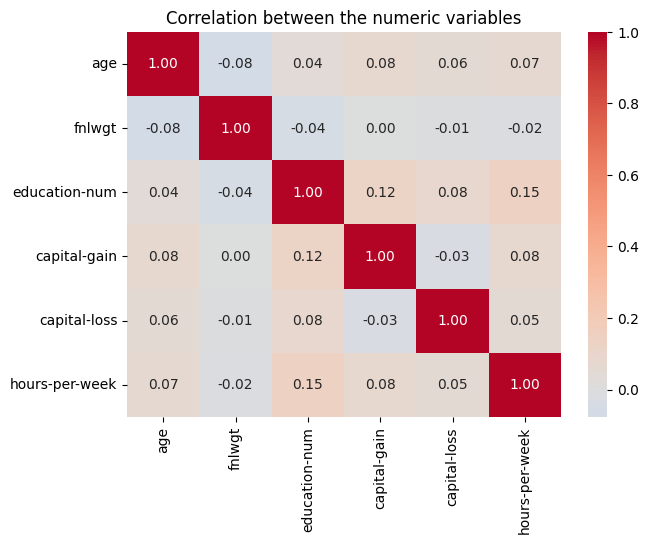

In [ ]:
# Correlation between the numeric variables
numeric_columns = income.select_dtypes(include='number').columns
correlation = income[numeric_columns].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation between the numeric variables')
plt.show()

A correlation heatmap puts the same variables on both axes and colors each cell
with the linear correlation of that pair, from minus one in blue to plus one in
red, with zero in white. The diagonal is always one because every variable is
perfectly correlated with itself.

The map is white almost everywhere. The largest value outside the diagonal is
0.148 between the education code and the hours per week, followed by 0.123
between the education code and the capital gain, and nothing else reaches 0.1 in
absolute value. So the six numeric columns say different things from one
another, there is no pair that duplicates information, and none of them has to
be dropped for being redundant with another.

What the map does not measure is the relationship of each variable with the
response, because `income` is text and is not in the matrix. The redundancy that
this dataset does have is between text columns, the marital status and the
relationship, and a linear correlation between numbers cannot see it.

In [ ]:
# Two columns are dropped, and this cell is the evidence for both decisions

# 1. education and education-num are the same variable written twice
pairs = income.groupby('education')['education-num'].nunique()
print("Different codes per education level:", pairs.unique())
print(income[['education', 'education-num']].drop_duplicates()
      .sort_values('education-num').to_string(index=False))

# 2. fnlwgt is a census sampling weight, it says how many people of the
# population the row represents, not what the person is like
target_numeric = (income['income'] == '>50K').astype(int)
print("\nCorrelation of fnlwgt with the response:",
      round(np.corrcoef(income['fnlwgt'], target_numeric)[0, 1], 4))
print("AUC of fnlwgt used alone as a score:",
      round(roc_auc_score(target_numeric, income['fnlwgt']), 4))

Different codes per education level: [1]
   education  education-num
   Preschool              1
     1st-4th              2
     5th-6th              3
     7th-8th              4
         9th              5
        10th              6
        11th              7
        12th              8
     HS-grad              9
Some-college             10
   Assoc-voc             11
  Assoc-acdm             12
   Bachelors             13
     Masters             14
 Prof-school             15
   Doctorate             16

Correlation of fnlwgt with the response: -0.0095
AUC of fnlwgt used alone as a score: 0.4927


This cell is the evidence for the only two columns that are removed.

The first line prints `[1]`, which means that every level of `education`
corresponds to exactly one value of `education-num`, and the table under it
shows the mapping in order, from `Preschool` at 1 to `Doctorate` at 16. The two
columns are the same variable written twice, once as a name and once as an
ordered code. Keeping both would add sixteen indicator columns that repeat a
single number, and the number is the better version of the two, because it
carries the order that the table of shares above showed to be real. `education`
is dropped and `education-num` is kept.

`fnlwgt` is dropped for the opposite reason. It is the final weight of the
census sample, a number that says how many people of the population the row is
meant to represent, so it describes the survey design and not the person. The
two measurements printed confirm that it carries nothing about the response: its
correlation with the response is -0.0095 and its AUC used alone as a score is
0.4927, where 0.5 is a coin flip. A forest given this column would still split on
it, because it has thousands of distinct values and every split lowers the
impurity of the training sample a little, so leaving it in would add noise to
the trees and to the importance ranking for no gain.

In [ ]:
# The response as a 0 and 1 variable, where 1 is the person of interest
target = (income['income'] == '>50K').astype(int)

# The predictors, without the two columns discarded above, and with every text
# column turned into indicator columns. The level '?' is kept as one more
# category instead of being filled in or dropped
predictors = pd.get_dummies(income.drop(columns=['income', 'fnlwgt',
                                                 'education']))

print("Columns of the original file:", income.shape[1])
print("Predictors before encoding:", income.shape[1] - 3)
print("Predictors after encoding:", predictors.shape[1])
print("\nClass counts of the recoded response:")
print(target.value_counts().sort_index())

Columns of the original file: 15
Predictors before encoding: 12
Predictors after encoding: 91

Class counts of the recoded response:
income
0    24698
1     7839
Name: count, dtype: int64


A random forest in scikit-learn only accepts numbers, so every text column has
to be turned into numbers first. `get_dummies` replaces a column by one
indicator column per level, holding 1 when the person belongs to that level and
0 otherwise, which is why the 12 predictors that survive the two drops become 91
columns. Most of that growth comes from `native-country`, which has 42 levels,
and from `occupation` with 15.

The level `?` becomes an indicator column like any other, which makes the
decision of the data understanding section concrete: the forest can now ask
whether the workclass is unknown and use the answer.

The response is recoded at the same time so that 1 means the person earns more
than 50000 and 0 means the person does not. This is only a renaming of the
labels, the counts are still 7839 and 24698, and it puts the class of interest
in the position that scikit-learn treats as positive when it computes precision,
recall and the ROC curve.

Training records: 26029
Test records: 6508
Total: 32537

Share above 50K in training: 0.241
Share above 50K in test: 0.241


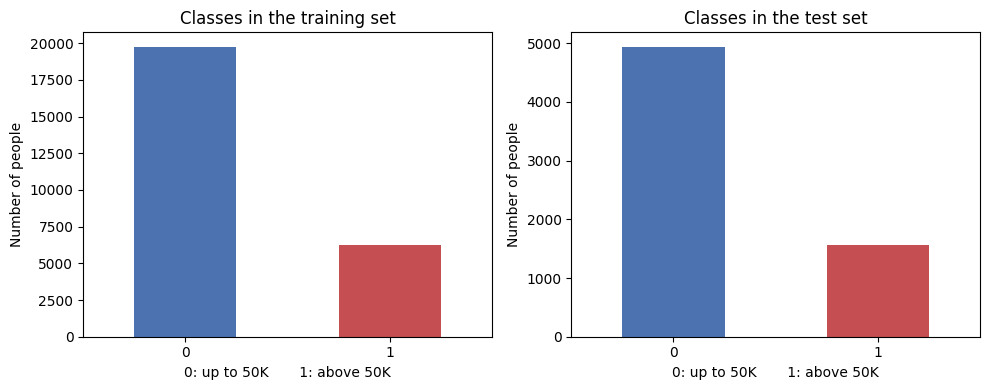

In [ ]:
# Split 80 percent for training and 20 percent for testing, keeping the
# proportion of people above 50K identical in both parts
X_train, X_test, y_train, y_test = train_test_split(
    predictors, target, test_size=0.2, random_state=SEED, stratify=target)

print("Training records:", len(X_train))
print("Test records:", len(X_test))
print("Total:", len(X_train) + len(X_test))
print()
print("Share above 50K in training:", round(y_train.mean(), 3))
print("Share above 50K in test:", round(y_test.mean(), 3))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
y_train.value_counts().sort_index().plot(kind='bar', color=['#4c72b0', '#c44e52'])
plt.title('Classes in the training set')
plt.xlabel('0: up to 50K       1: above 50K')
plt.ylabel('Number of people')
plt.xticks(rotation=0)
plt.subplot(1, 2, 2)
y_test.value_counts().sort_index().plot(kind='bar', color=['#4c72b0', '#c44e52'])
plt.title('Classes in the test set')
plt.xlabel('0: up to 50K       1: above 50K')
plt.ylabel('Number of people')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The model is fitted on one part of the data and judged on another part it has
never seen, otherwise the score would only say how well it memorised. Here 26029
records go to training and 6508 to testing, and nothing is lost since the two add
up to the 32537 records that remained after the duplicates were removed.

The split is stratified, which means the share of people above 50000 is forced to
be the same in both parts. Both bar charts show the same shape and both means
print 0.241, so a difference between the two sets later on cannot be blamed on
one of them holding more high earners than the other.

From this point until the evaluation section, only `X_train` and `y_train` are
used. Every parameter of the forest is chosen with cross validation inside the
training set, so the 6508 test records stay untouched and the numbers they
produce at the end are not contaminated by the choices made to build the model.

## Machine Learning Model (CRISP-DM 4: Modeling)

A random forest is a collection of decision trees that vote. Each tree is
fitted on a bootstrap sample of the training records, which is a sample of the
same size drawn with replacement, so about a third of the records are left out
of every tree, and at each node the tree may only choose among a random subset
of the columns. Those two sources of randomness make the trees different from
one another, and averaging many different trees cancels part of the error that
any single one of them makes.

Three parameters decide the shape of the forest and each one is chosen below
with its own evidence, always inside the training set:

* `n_estimators`, the number of trees, chosen with the out of bag score, which
  scores every record with the trees that did not see it and therefore needs no
  extra split.
* `min_samples_leaf`, the smallest number of records a leaf may hold, which stops each individual tree from describing its sample one record at a
  time.
* `max_features`, how many columns a node may choose among, which controls how
  different the trees are from one another.

The metric used for the last two is the AUC, the area under the ROC curve
explained in the evaluation section, because it measures how well the model
orders people by their probability of earning more than 50000 without depending
on where the decision cut is placed.

site-packages\sklearn\ensemble\_forest.py:611: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


n_estimators 10   out of bag accuracy 0.8335


n_estimators 25   out of bag accuracy 0.8448


n_estimators 50   out of bag accuracy 0.8471


n_estimators 100   out of bag accuracy 0.8487


n_estimators 200   out of bag accuracy 0.8501


n_estimators 300   out of bag accuracy 0.8502


n_estimators 500   out of bag accuracy 0.8511


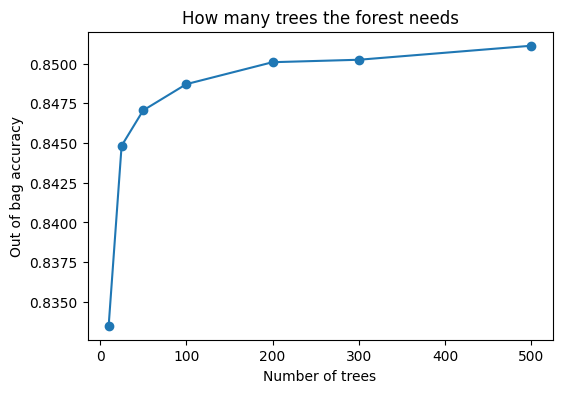

In [ ]:
# Number of trees, judged by the out of bag score. Every record is predicted
# with the trees that did not draw it in their bootstrap sample, so this
# estimate costs nothing and does not touch the test set
tree_counts = [10, 25, 50, 100, 200, 300, 500]
oob_scores = []
for count in tree_counts:
    candidate = RandomForestClassifier(n_estimators=count, random_state=1,
                                       oob_score=True, n_jobs=-1)
    candidate.fit(X_train, y_train)
    oob_scores.append(candidate.oob_score_)
    print("n_estimators", count, "  out of bag accuracy",
          round(candidate.oob_score_, 4))

plt.figure(figsize=(6, 4))
plt.plot(tree_counts, oob_scores, marker='o')
plt.xlabel('Number of trees')
plt.ylabel('Out of bag accuracy')
plt.title('How many trees the forest needs')
plt.show()

The out of bag score works because of how the forest is built. Each tree draws
its own bootstrap sample, and the records that were not drawn, about a third of
them, are records that tree has never seen, so every record can be predicted by
the subset of trees that left it out. That gives an honest estimate of the error
without spending a single record on a validation set.

The curve rises steeply and then stops. Ten trees give 0.8335, twenty five give
0.8448, and from there the gains shrink to 0.8471, 0.8487 and 0.8501 at 200
trees. Three hundred trees give 0.8502 and five hundred give 0.8511, so the last
three hundred trees buy 0.0009 of accuracy, which is about two dozen records
out of the 26029 of the training set.

The warning printed for the first row belongs to the same mechanism: with only
ten trees some records happen to be drawn by all of them and have no tree left
to predict them, so their out of bag score cannot be computed.

The forest is built with 300 trees. The curve is flat from 200 onwards, more
trees never make a forest worse, they only cost time, and 300 sits inside the
flat region with room to spare.

min_samples_leaf 1   mean AUC 0.894


min_samples_leaf 2   mean AUC 0.9185


min_samples_leaf 5   mean AUC 0.9174


min_samples_leaf 10   mean AUC 0.9156


min_samples_leaf 20   mean AUC 0.9132


min_samples_leaf 50   mean AUC 0.9088


min_samples_leaf 100   mean AUC 0.9043

Best min_samples_leaf: 2


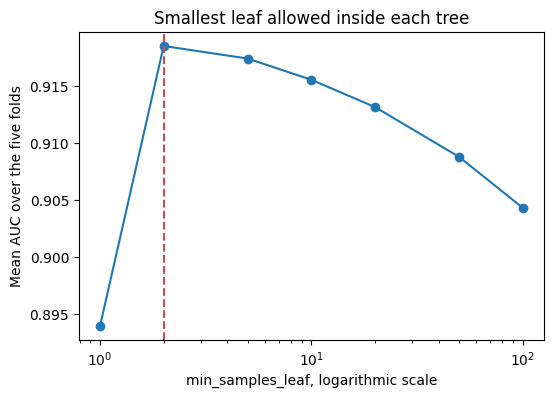

In [ ]:
# Smallest size allowed for a leaf, scored with 5 fold cross validation on the
# training set only
leaf_sizes = [1, 2, 5, 10, 20, 50, 100]
leaf_scores = []
for leaf in leaf_sizes:
    candidate = RandomForestClassifier(n_estimators=200, min_samples_leaf=leaf,
                                       random_state=1, n_jobs=-1)
    score = cross_val_score(candidate, X_train, y_train, cv=5,
                            scoring='roc_auc').mean()
    leaf_scores.append(score)
    print("min_samples_leaf", leaf, "  mean AUC", round(score, 4))

best_leaf = leaf_sizes[int(np.argmax(leaf_scores))]
print("\nBest min_samples_leaf:", best_leaf)

plt.figure(figsize=(6, 4))
plt.plot(leaf_sizes, leaf_scores, marker='o')
plt.axvline(best_leaf, color='#c44e52', linestyle='--')
plt.xscale('log')
plt.xlabel('min_samples_leaf, logarithmic scale')
plt.ylabel('Mean AUC over the five folds')
plt.title('Smallest leaf allowed inside each tree')
plt.show()

`min_samples_leaf` stops each individual tree from growing until every leaf
holds a single record. The default is 1, which means no limit at all, and that
default turns out to be the worst value of the seven tried: it scores 0.8940 of
AUC against 0.9185 for a leaf of 2, a difference of 0.0245 that dwarfs
everything else in this table.

The reason is that a leaf with one record describes that record and nobody else.
With 91 indicator columns available there is almost always a combination that
isolates a single person, so the trees end up voting on individuals they
memorised rather than on groups, and the probabilities they average become
coarse and extreme. Asking for two records per leaf is a very small constraint
and it is enough to stop that.

From there the curve declines slowly and steadily: 0.9174 at 5, 0.9156 at 10,
0.9132 at 20, 0.9088 at 50 and 0.9043 at 100. Those are trees that are being
forced to stay too shallow and start losing real detail, and the fall is gentle
because the forest averages many of them. The value used from here on is 2.

In [ ]:
# How many columns a node may choose among, with the leaf size already fixed
feature_options = ['sqrt', 'log2', 0.3, 0.5, None]
feature_scores = []
for option in feature_options:
    candidate = RandomForestClassifier(n_estimators=200,
                                       min_samples_leaf=best_leaf,
                                       max_features=option,
                                       random_state=1, n_jobs=-1)
    score = cross_val_score(candidate, X_train, y_train, cv=5,
                            scoring='roc_auc').mean()
    feature_scores.append(score)
    columns_used = (int(np.sqrt(X_train.shape[1])) if option == 'sqrt'
                    else int(np.log2(X_train.shape[1])) if option == 'log2'
                    else X_train.shape[1] if option is None
                    else int(option * X_train.shape[1]))
    print(str(option).ljust(5), " columns per node:", str(columns_used).ljust(3),
          " mean AUC", round(score, 4))

best_features = feature_options[int(np.argmax(feature_scores))]
print("\nBest max_features:", best_features)

sqrt   columns per node: 9    mean AUC 0.9185


log2   columns per node: 6    mean AUC 0.9169


0.3    columns per node: 27   mean AUC 0.9142


0.5    columns per node: 45   mean AUC 0.9101


None   columns per node: 91   mean AUC 0.9043

Best max_features: sqrt


`max_features` is the parameter that makes the trees different from one another.
At each node the tree may only look at a random subset of the columns, so two
trees that saw the same records still ask different questions, and the vote of a
group of different trees is worth more than the vote of a group of identical
ones.

The table reads in one direction. Nine columns per node, which is the square root
of 91 and the default of the library, give 0.9185; six columns give 0.9169; and
from there every increase makes the forest worse, 0.9142 with 27 columns, 0.9101
with 45 and 0.9043 with all 91.

That last row is the important one. Letting every node see every column removes
the randomness of the columns entirely, so the only thing left separating the
trees is the bootstrap sample, they all find the same strong split at the top and
the forest turns into 300 copies of nearly the same tree. It loses 0.0142 of AUC
against the default, which is more than everything the leaf size gained after
the first step. The default `sqrt` is kept.

In [ ]:
# Train the forest with the three parameters chosen above
forest = RandomForestClassifier(n_estimators=300,
                                min_samples_leaf=best_leaf,
                                max_features=best_features,
                                random_state=1, oob_score=True, n_jobs=-1)
forest.fit(X_train, y_train)

print("Accuracy on training:", round(forest.score(X_train, y_train), 4))
print("Out of bag accuracy:", round(forest.oob_score_, 4))
print("Accuracy on test:", round(forest.score(X_test, y_test), 4))
print()
print("Accuracy of answering '<=50K' to everybody:",
      round(1 - y_test.mean(), 4))

Accuracy on training: 0.8974
Out of bag accuracy: 0.8655
Accuracy on test: 0.8596

Accuracy of answering '<=50K' to everybody: 0.7591


The forest is now fitted with the three parameters chosen inside the training
set: 300 trees, at least 2 records per leaf and 9 columns offered at each node.

The three accuracies printed have to be read in order. The 0.8974 on the
training records says almost nothing, because those are the records the trees
were built from. The out of bag accuracy of 0.8655 is the honest one, since it
scores every training record with the trees that did not see it. And the test
accuracy of 0.8596 is the one that will be reported, measured on 6508 records
that took no part in anything so far.

The two honest numbers agree to within 0.006, which is the practical value of
the out of bag estimate: it saw the model coming before the test set was touched.
The distance between the training accuracy and the other two, 0.038, is the part
of the fit that does not generalise, and it is small for a model of this size.

The last line is the comparison that matters. Answering `<=50K` to every one of
the 6508 test records would score 0.7591, so the forest is 10 points above the
answer that requires no model at all. The evaluation section takes that apart,
because accuracy hides where those 10 points come from.

                         Variable  Importance
                     capital-gain    0.149984
                    education-num    0.145983
marital-status_Married-civ-spouse    0.121071
                              age    0.107268
             relationship_Husband    0.075201
                   hours-per-week    0.065039
                     capital-loss    0.040825
     marital-status_Never-married    0.036968
       occupation_Exec-managerial    0.026470
        occupation_Prof-specialty    0.025633
       relationship_Not-in-family    0.016372
                relationship_Wife    0.016311

Variables the forest never used: 2 of 91


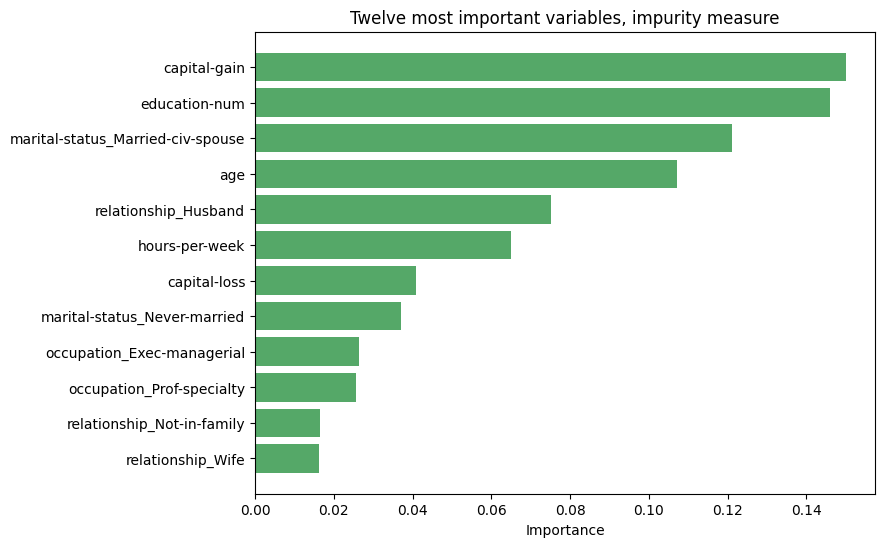

In [ ]:
# Importance of each variable for the forest, measured on the impurity the
# splits remove and averaged over the 300 trees
forest_importances = pd.DataFrame({
    'Variable': forest.feature_names_in_,
    'Importance': forest.feature_importances_
}).sort_values('Importance', ascending=False)

top_forest = forest_importances.head(12)
print(top_forest.to_string(index=False))
print("\nVariables the forest never used:",
      int((forest_importances['Importance'] == 0).sum()), "of",
      len(forest_importances))

plt.figure(figsize=(8, 6))
plt.barh(top_forest['Variable'][::-1], top_forest['Importance'][::-1],
         color='#55a868')
plt.title('Twelve most important variables, impurity measure')
plt.xlabel('Importance')
plt.show()

The importance of a variable is how much the splits made on it reduced the
impurity of the nodes, weighted by how many records passed through those splits
and averaged over the 300 trees, and the importances of all the variables add up
to 1.

The ranking reproduces the exploration. The capital gain leads with 0.150, the
education code follows with 0.146, being married with a civilian spouse takes
0.121 and the age 0.107. Then come being a husband with 0.075, the hours per week
with 0.065 and the capital loss with 0.041, and after that the values fall below
0.04 and spread over the levels of the occupation. Only 2 of the 91 columns were
never used, because each tree is offered a different random subset of columns and
even the rare levels get their chance somewhere among the 300 of them.

The measure has two problems. The first is that this measure favours the
variables with many distinct values, because a variable with more possible cut
points gets more opportunities to produce a good split, which helps `age`,
`capital-gain` and `hours-per-week` and hurts the indicator columns that can
only be cut at 0.5. The second is the redundancy the exploration found: the
fact of being married is spread over `marital-status_Married-civ-spouse` and
`relationship_Husband`, so neither number alone measures how much that fact is
worth.

The next cell answers both cautions with a second measure that does not depend
on how the trees were built.

                         Variable  AUC lost  Standard deviation
                     capital-gain    0.0361              0.0011
                    education-num    0.0235              0.0012
marital-status_Married-civ-spouse    0.0223              0.0016
                              age    0.0199              0.0017
                   hours-per-week    0.0111              0.0017
                     capital-loss    0.0088              0.0004
             relationship_Husband    0.0051              0.0005
       occupation_Exec-managerial    0.0038              0.0007
        occupation_Prof-specialty    0.0033              0.0002
         occupation_Other-service    0.0024              0.0003
     marital-status_Never-married    0.0019              0.0003
                relationship_Wife    0.0017              0.0001


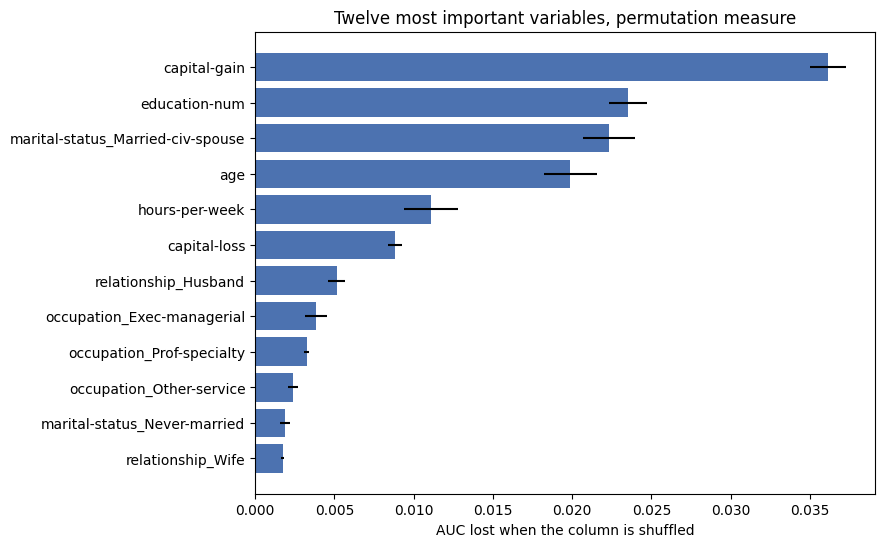

In [ ]:
# Second measure of importance: shuffle one column of the test set and see how
# much AUC the forest loses. A variable that does not matter loses nothing
permutation = permutation_importance(forest, X_test, y_test, n_repeats=5,
                                     random_state=SEED, n_jobs=-1,
                                     scoring='roc_auc')

permutation_table = pd.DataFrame({
    'Variable': forest.feature_names_in_,
    'AUC lost': permutation.importances_mean,
    'Standard deviation': permutation.importances_std
}).sort_values('AUC lost', ascending=False)

top_permutation = permutation_table.head(12)
print(top_permutation.round(4).to_string(index=False))

plt.figure(figsize=(8, 6))
plt.barh(top_permutation['Variable'][::-1], top_permutation['AUC lost'][::-1],
         xerr=top_permutation['Standard deviation'][::-1], color='#4c72b0')
plt.title('Twelve most important variables, permutation measure')
plt.xlabel('AUC lost when the column is shuffled')
plt.show()

The permutation importance asks a different question. The forest is left
exactly as it is, one column of the test set is shuffled so that its values no
longer belong to the right person, and the AUC is measured again. The drop in
AUC measures what the column was worth. The whole thing is repeated five times
per column and the standard deviation of those five repetitions is printed next
to the mean, so a value can be compared against its own noise.

The two measures agree on what matters. The capital gain leads again and costs
0.0361 of AUC when it is shuffled, followed by the education code with 0.0235,
being married with a civilian spouse with 0.0223 and the age with 0.0199. All
four are more than ten times their standard deviation, so none of them is an
accident of the five repetitions.

The disagreement is instructive. `relationship_Husband` was fifth by impurity
with 0.075 and falls to seventh here with 0.0051. That is the redundancy showing
its other face: shuffling the husband column alone barely hurts the forest,
because `marital-status_Married-civ-spouse` is still there to say the same thing.
Permutation importance measures what a column is worth given the others, not what
it is worth on its own, and two columns that repeat a fact will both look cheap
when tested one at a time.

The absolute values are small because the AUC starts at 0.9152 and no single
column carries the model. Losing the strongest predictor of the 91 costs about
four hundredths of AUC, which happens when an ensemble spreads its decision
over many variables.

## Evaluation (CRISP-DM 5)

The forest is now applied to the test records it has never seen. The first tool
is the confusion matrix, which crosses the real class with the predicted one.
Its four cells are the people correctly predicted below 50000, the people
wrongly flagged as earning more, the people above 50000 the model missed, and
the ones it found.

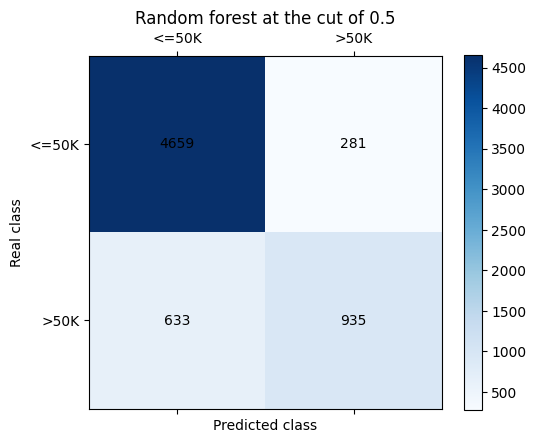

              precision    recall  f1-score   support

       <=50K      0.880     0.943     0.911      4940
        >50K      0.769     0.596     0.672      1568

    accuracy                          0.860      6508
   macro avg      0.825     0.770     0.791      6508
weighted avg      0.854     0.860     0.853      6508



In [ ]:
# Probability of earning more than 50000 that the forest assigns to every test
# record
forest_scores = forest.predict_proba(X_test)[:, 1]

# One single rule turns those probabilities into decisions, so every matrix and
# table of this section is produced under an explicit cut and never through
# predict()
DECISION_THRESHOLD = 0.5

def decisions_at(scores, threshold):
    return (scores >= threshold).astype(int)

forest_predictions = decisions_at(forest_scores, DECISION_THRESHOLD)
forest_matrix = confusion_matrix(y_test, forest_predictions)

labels = ['<=50K', '>50K']
fig, ax = plt.subplots(figsize=(5.5, 4.5))
image = ax.matshow(forest_matrix, cmap=plt.cm.Blues)
for i in range(forest_matrix.shape[0]):
    for j in range(forest_matrix.shape[1]):
        ax.text(x=j, y=i, s=forest_matrix[i, j], va='center', ha='center')
ax.set_xlabel('Predicted class')
ax.set_ylabel('Real class')
ax.set_xticks([0, 1], labels)
ax.set_yticks([0, 1], labels)
ax.set_title('Random forest at the cut of 0.5')
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

print(classification_report(y_test, forest_predictions,
                            target_names=labels, digits=3))

The rows of the matrix are the real class and the columns the predicted one, so
the diagonal holds the correct answers. The report under the plot turns the four
cells into three rates for each class. Precision is how many of the people
flagged as earning more than 50000 really do, recall is how many of the real
high earners the model found, and the F1 is the balance between those two.

Read on the majority class the model looks excellent: precision 0.880 and recall
0.943, so of the 4940 people at or below 50000 it classifies 4659 correctly.
Read on the class the notebook was built for it looks much worse. Of the 1568
people above 50000 it finds 935, a recall of 0.596, and lets 633 through. Its
precision on them is 0.769, so of the 1216 people it flags, 935 really are above
50000.

The accuracy of 0.860 is the average of those two very different behaviours,
weighted by class sizes that are themselves very different, which is exactly why
it is the wrong number to judge this model by. Missing four high earners out of
ten costs almost nothing in accuracy, because the people missed are a quarter of
the data, and it costs everything to whoever wanted to find them.

The cut of 0.5 produces this. The model was not asked whether the person earns
more than 50000, it was asked whether at least half of its probability says so,
and with 24 percent of the records in that class the probabilities rarely reach
that. The next two cells take that apart.

AUC of the random forest: 0.9152


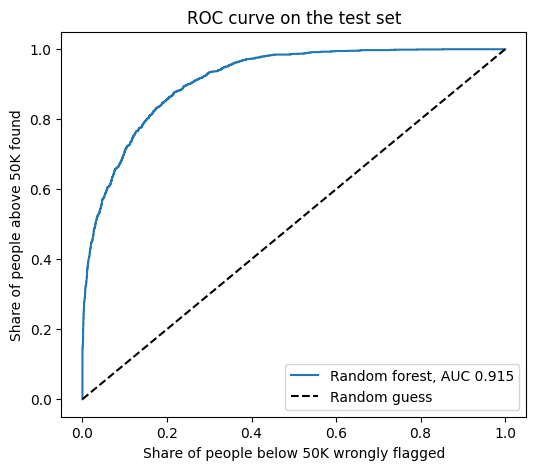

In [ ]:
# ROC curve, built from the probabilities computed above
forest_auc = roc_auc_score(y_test, forest_scores)
print("AUC of the random forest:", round(forest_auc, 4))

fpr, tpr, _ = roc_curve(y_test, forest_scores)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label='Random forest, AUC ' + str(round(forest_auc, 3)))
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('Share of people below 50K wrongly flagged')
plt.ylabel('Share of people above 50K found')
plt.title('ROC curve on the test set')
plt.legend()
plt.show()

The forest does not really answer yes or no, it returns a probability, and the
predictions of the previous cell came from cutting that probability at 0.5. The
ROC curve redoes the comparison for every possible cut: the horizontal axis is
the share of people below 50000 wrongly flagged and the vertical one the share of
people above 50000 found, and each point of the curve is one cut. The diagonal is
what a coin flip would draw. The area under the curve, the AUC, summarises it in
one number, and it can be read as the probability that the model gives a higher
score to a random person above 50000 than to a random person below.

The AUC is 0.9152. Taking two people at random, one from each class, the forest
ranks them correctly nine times out of ten, and the curve climbs steeply from the
origin, so the people it is most confident about really are high earners.

That number and the recall of 0.596 of the previous cell describe the same
model, and the gap between them needs explaining. The forest orders people by
income very well and decides badly, which means the problem is not what it
learned but where the line was drawn. A cut is not part of the model, it is a
choice made afterwards, and the next cell makes it deliberately instead of
accepting the default.

F1 on the training folds at the cut of 0.5: 0.6919
Best cut on the training folds: 0.36
F1 on the training folds at that cut: 0.7176


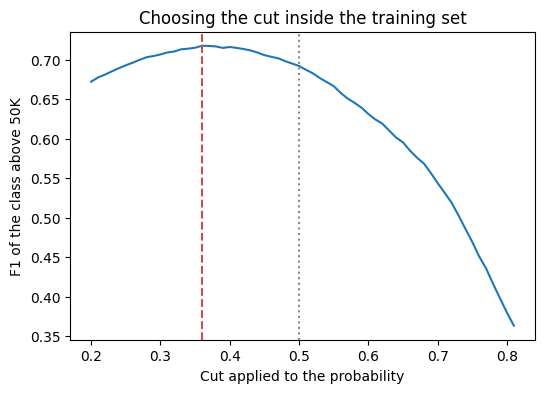

In [ ]:
# The cut is chosen inside the training set, never on the test set. Every
# training record is scored by the folds that did not contain it, and the cut
# that maximises the F1 of the minority class on those scores is kept
out_of_fold = cross_val_predict(
    RandomForestClassifier(n_estimators=300, min_samples_leaf=best_leaf,
                           max_features=best_features, random_state=1,
                           n_jobs=-1),
    X_train, y_train, cv=5, method='predict_proba')[:, 1]

cut_grid = np.arange(0.20, 0.81, 0.01)
cut_scores = [f1_score(y_train, decisions_at(out_of_fold, cut))
              for cut in cut_grid]
best_cut = round(float(cut_grid[int(np.argmax(cut_scores))]), 2)

print("F1 on the training folds at the cut of 0.5:",
      round(f1_score(y_train, decisions_at(out_of_fold, 0.5)), 4))
print("Best cut on the training folds:", best_cut)
print("F1 on the training folds at that cut:", round(max(cut_scores), 4))

plt.figure(figsize=(6, 4))
plt.plot(cut_grid, cut_scores)
plt.axvline(best_cut, color='#c44e52', linestyle='--')
plt.axvline(0.5, color='#888888', linestyle=':')
plt.xlabel('Cut applied to the probability')
plt.ylabel('F1 of the class above 50K')
plt.title('Choosing the cut inside the training set')
plt.show()

The cut has to be chosen somewhere, and choosing it on the test set would spend
the only untouched data the notebook has left. `cross_val_predict` avoids that:
it cuts the training set into five blocks, fits the forest five times leaving one
block out, and returns for every training record the probability given by the
folds that did not contain it. Those 26029 probabilities are as close to
out of sample as the training set can get, and the cut is chosen on them.

The criterion is the F1 of the class above 50000, which is the harmonic mean of
precision and recall, because it is the standard way of asking for a decision
that finds the minority class without flagging everybody. The dataset comes with
no cost per error, so nothing better than F1 is available here.

The result is 0.36 with an F1 of 0.7176, against 0.6919 at the default cut of
0.5. The curve around the maximum is smooth, and every cut between 0.33 and 0.42
scores within 0.005 of the best, so 0.36 should be read as the middle of a
plateau rather than as a precise value, and the next cell shows the neighbouring
cuts on the test set.

In [ ]:
# What the cut chosen on the training folds does on the test set, next to the
# neighbouring cuts
rows = []
for threshold in [0.30, 0.35, best_cut, 0.40, 0.45, 0.50, 0.60]:
    predicted = decisions_at(forest_scores, threshold)
    rows.append({
        'Threshold': threshold,
        'Accuracy': round(accuracy_score(y_test, predicted), 3),
        'Precision': round(precision_score(y_test, predicted), 3),
        'Recall': round(recall_score(y_test, predicted), 3),
        'F1': round(f1_score(y_test, predicted), 3),
        'Missed above 50K': int(((y_test == 1) & (predicted == 0)).sum()),
        'Wrongly flagged': int(((y_test == 0) & (predicted == 1)).sum())
    })
table = pd.DataFrame(rows).drop_duplicates(subset='Threshold').sort_values('Threshold')
print(table.to_string(index=False))

 Threshold  Accuracy  Precision  Recall    F1  Missed above 50K  Wrongly flagged
      0.30     0.833      0.617   0.812 0.701               295              789
      0.35     0.847      0.657   0.762 0.706               373              623
      0.36     0.848      0.664   0.747 0.703               396              593
      0.40     0.853      0.692   0.705 0.698               463              491
      0.45     0.858      0.731   0.654 0.690               543              378
      0.50     0.860      0.769   0.596 0.672               633              281
      0.60     0.855      0.844   0.487 0.618               804              141


Each row applies a different cut to the same probabilities and recounts the
errors, with the two columns on the right counting the two mistakes directly, so
the table can be read as a menu of decisions rather than as a list of scores.

The cut of 0.36 chosen on the training folds gives an F1 of 0.703 on the test
set. The best F1 available on this test set is 0.706 at a cut of 0.35, so the
procedure landed one hundredth of a step away from the best it could have done,
and it did so without looking at these records. That agreement is the evidence
that the cut was chosen properly.

The trade behind the move is explicit in the last two columns. At 0.5 the model
misses 633 people above 50000 and wrongly flags 281; at 0.36 it misses 396 and
flags 593. So 237 more high earners are found at the price of 312 more false
flags, recall goes from 0.596 to 0.747 and precision from 0.769 to 0.664.

Accuracy moves the other way, from 0.860 down to 0.848. The cut that maximises
accuracy and the cut that finds the class of interest are not the same cut, and
1.2 points of accuracy is the price this model pays to recover a third of the
people it was letting through.

The right end of the table shows what happens if the cut is pushed the other
way: at 0.60 the precision climbs to 0.844 but the recall falls to 0.487, so the
model becomes a tool for finding a small, very reliable group instead of a tool
for finding the group.

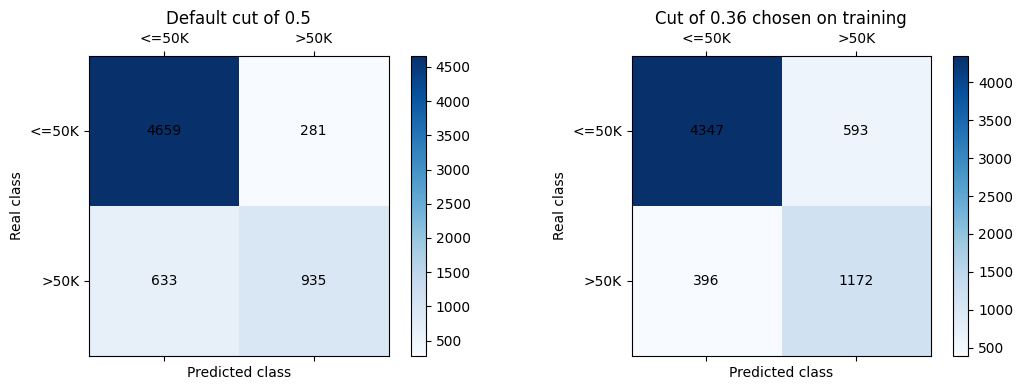

              precision    recall  f1-score   support

       <=50K      0.917     0.880     0.898      4940
        >50K      0.664     0.747     0.703      1568

    accuracy                          0.848      6508
   macro avg      0.790     0.814     0.801      6508
weighted avg      0.856     0.848     0.851      6508



In [ ]:
# The two decisions side by side on the test set
chosen_predictions = decisions_at(forest_scores, best_cut)
chosen_matrix = confusion_matrix(y_test, chosen_predictions)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
names = ['Default cut of 0.5', 'Cut of ' + str(best_cut) + ' chosen on training']
for ax, matrix, name in zip(axes, [forest_matrix, chosen_matrix], names):
    image = ax.matshow(matrix, cmap=plt.cm.Blues)
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(x=j, y=i, s=matrix[i, j], va='center', ha='center')
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('Real class')
    ax.set_xticks([0, 1], labels)
    ax.set_yticks([0, 1], labels)
    ax.set_title(name)
    fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

print(classification_report(y_test, chosen_predictions,
                            target_names=labels, digits=3))

The two matrices are the same forest read with two different cuts. On the left,
at 0.5, the model finds 935 of the 1568 people above 50000. On the right, at
0.36, it finds 1172 of them, and the cell of the people it misses falls from 633
to 396.

The cost is in the top right cell, which grows from 281 to 593, so the number of
people wrongly flagged more than doubles. The report under the plots puts that in
rates: precision 0.664 and recall 0.747 on the class above 50000, for an F1 of
0.703 against the 0.672 of the default cut.

The macro average, which weighs the two classes equally instead of by their size,
goes from 0.791 to 0.801, and it is the number that best summarises what changed:
the model is now roughly as good at one class as at the other, which the cut of
0.5 never was.

### Model persistence

The recommended model is saved to disk so it can be reused without training it
again, which makes a fitted model usable outside the notebook. What has to
travel with the forest is not only the 300 trees: the columns produced by
`get_dummies` and the cut chosen on the training folds are part of the
decision, so a new record has to be encoded exactly like the training data
before the model can score it.

The saved file is loaded back and asked for the same prediction on the first
test records, and the two answers are compared, so the copy on disk is verified
to behave like the model that was just fitted.

In [ ]:
# What is saved: the forest, the columns it expects and the cut it is read with
bundle = {'model': forest,
          'columns': list(predictors.columns),
          'threshold': best_cut}

# 300 trees of this size take tens of megabytes raw, so the file is compressed
joblib.dump(bundle, 'model_income_forest.pkl', compress=3)
print("Size on disk:",
      round(os.path.getsize('model_income_forest.pkl') / 1024 / 1024, 2), "MB")

# Load it back and predict with the copy from disk, on five test records of
# each class so both answers can be seen
sample_index = pd.concat([y_test[y_test == 0].head(5),
                          y_test[y_test == 1].head(5)]).index
loaded = joblib.load('model_income_forest.pkl')
sample = X_test.loc[sample_index, loaded['columns']]
loaded_scores = loaded['model'].predict_proba(sample)[:, 1]
original_scores = forest.predict_proba(sample)[:, 1]

print("\nThe copy on disk answers exactly like the fitted model:",
      bool(np.allclose(loaded_scores, original_scores)))

check = pd.DataFrame({
    'Age': income.loc[sample_index, 'age'].values,
    'Education': income.loc[sample_index, 'education'].values,
    'Hours': income.loc[sample_index, 'hours-per-week'].values,
    'Probability above 50K': np.round(loaded_scores, 3),
    'Decision at the cut': np.where(loaded_scores >= loaded['threshold'],
                                    '>50K', '<=50K'),
    'Real class': np.where(y_test.loc[sample_index] == 1, '>50K', '<=50K')
})
print()
print(check.to_string(index=False))

Size on disk: 14.03 MB



The copy on disk answers exactly like the fitted model: True

 Age    Education  Hours  Probability above 50K Decision at the cut Real class
  25      Masters     20                  0.048               <=50K      <=50K
  31      HS-grad     45                  0.045               <=50K      <=50K
  48      HS-grad     40                  0.023               <=50K      <=50K
  47 Some-college     40                  0.408                >50K      <=50K
  30         11th     40                  0.019               <=50K      <=50K
  43    Bachelors     37                  0.653                >50K       >50K
  28    Bachelors     45                  0.487                >50K       >50K
  36      Masters     50                  0.949                >50K       >50K
  41    Bachelors     40                  0.673                >50K       >50K
  62  Prof-school     15                  0.408                >50K       >50K


The file weighs 14 MB compressed, the cost of 300 trees of this depth, and the
check prints `True`: the copy loaded from disk assigns exactly the same
probabilities as the model that was just fitted.

The table below is the model working record by record on ten test people, five of
each class, with three of their attributes printed next to the answer. Nine of
the ten are classified correctly. The one that is not is the fourth row, a person
of 47 with some college and 40 hours a week, who receives a probability of 0.408
and is flagged as above 50000 because the cut is 0.36, while the real answer is
below. At the default cut of 0.5 that person would have been classified
correctly, but two of the five people above 50000, the ones scoring 0.487 and
0.408, would have been lost, so these ten rows show both sides of the trade the
previous section measured.

The last row is worth reading too: a person of 62 with a professional school
degree working 15 hours a week gets 0.408, the same probability as the false
positive, and this time the answer is above 50000. A probability of 0.4 means
exactly that, two people with the same score and different outcomes, and it is
the reason the output of this model is a score to be ranked and not a verdict.

## Results (CRISP-DM 6: Deployment)

A random forest of 300 trees was trained on 26029 census records and judged on
6508 that it never saw, to classify a person as earning more or less than 50000
dollars a year. Its three parameters were chosen inside the training set: 300
trees from the out of bag curve, a minimum of 2 records per leaf and 9 columns
offered at each node from five fold cross validation on the AUC.

The model works. On the test set it reaches an AUC of 0.9152, so taking one
person from each class at random it ranks them correctly nine times out of ten,
and an accuracy of 0.8596 against the 0.7591 that answering `<=50K` to everybody
would give. The out of bag estimate had announced that result before the test set
was touched, 0.8655 against the 0.8596 measured afterwards.

Where the model is read matters as much as the model. At the default cut of 0.5
it finds only 935 of the 1568 people above 50000, a recall of 0.596, because with
24 percent of the records in that class the probabilities rarely reach one half.
The cut was therefore chosen on the training folds by cross validation, which
gave 0.36, and at that cut the model finds 1172 of the 1568, a recall of 0.747
and an F1 of 0.703 against 0.672. It pays 312 additional false flags and 1.2
points of accuracy for 237 more people found. The cut chosen without looking at
the test set landed within one hundredth of the best cut available on it, 0.703
against 0.706 at 0.35, which is the evidence that the procedure was sound.

What drives the prediction is consistent across the two measures of importance
and matches what the exploration had shown. The capital gain leads both rankings,
costing 0.036 of AUC when it is shuffled, followed by the education code, being
married with a civilian spouse and the age, and then the hours per week and the
capital loss. The education code orders the classes without a single inversion,
from 0.000 above 50000 for preschool to 0.741 for a doctorate, and being married
with a civilian spouse separates 44.7 percent from the 4.6 percent of the people
who never married. The two rankings disagree on `relationship_Husband`, fifth by
impurity and seventh by permutation, which is the redundancy between the marital
status and the relationship showing up: shuffling one of two columns that say the
same thing costs little, because the other one remains.

The recommendation is to deploy the forest as a scoring tool and not as a verdict.
Its output is a probability, its value is the ordering it produces, and the cut
of 0.36 should be treated as one option on the curve rather than as a property of
the model: whoever uses it has to say what a missed high earner and a false flag
are worth to them, and read the table of cuts accordingly. With a precision of
0.664 at that cut, one of every three people it flags earns at most 50000.

The model has five limitations.

The data is the census of the United States of 1994 and the threshold is 50000
dollars of that year, worth roughly twice as much as 50000 dollars today, so the
model answers a question about a population that no longer exists and cannot be
applied to current records without being refitted.

The 159 records whose capital gain is exactly 99999 are the census top code, not
a real amount, and all of them are above 50000. That value is a label of the
answer hidden inside a predictor, and since the capital gain is the strongest
variable of the model, part of its importance is that artefact rather than
information a new record would carry.

The gap between men and women, 30.6 percent above 50000 against 11.0 percent, is
in the data and the model reproduces it, and the same applies to the differences
by race and by country of origin. A forest fitted on this file will assign a
lower probability to a woman with otherwise identical attributes. Using this
model to decide anything about a person would propagate the inequality of 1994
labour market, so any deployment has to either remove those columns and measure
what it loses, or restrict the model to uses where that propagation does not
occur.

The 2399 records with an unknown workclass, occupation or country were kept with
`?` as an explicit level, which the exploration justified, but that level mixes
several situations that the file does not distinguish, and a model that learns
that unknown means low income is learning something about how the survey was
answered rather than about the person.

Finally, the cut of 0.36 was chosen on the training folds and evaluated on the
test set once. Repeating the whole procedure with another seed would move it
inside the plateau between 0.33 and 0.42, and every rate reported here carries
the noise of 1568 positive records, so differences of a few thousandths between
two configurations should not be read as real.